In [15]:
import random
import numpy as np 
import matplotlib.pyplot as plt
from datetime import datetime, timezone
import dukascopy_python.compat as duka
from dukascopy_python.compat.instruments import (
    INSTRUMENT_FX_MAJORS_EUR_USD,
)
import os, sys
sys.path.append(os.path.abspath(".."))   # ".." = thư mục cha của notebooks/ = algo-ml
%load_ext autoreload
%autoreload 2            

from src import data

In [2]:
nwalks = 1000
nsteps = 250
rng = np.random.default_rng(42)
draw = rng.integers(0,2,size = (nwalks,nsteps))
step = np.where(draw > 0, 1,-1)
walks = step.cumsum(axis = 1)


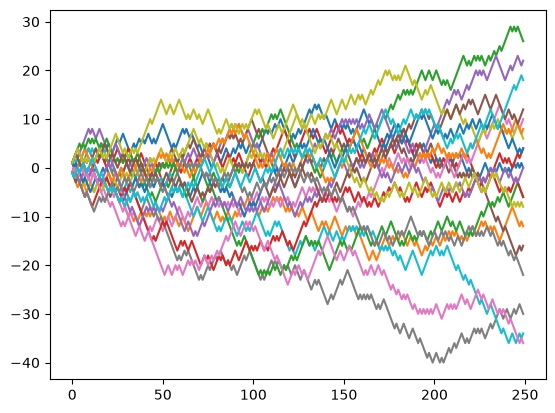

In [3]:
plt.plot(walks[:20].T)
plt.show()

In [4]:
cross_over = (np.abs(walks[:,-1:]) > 15.8).any(axis = 1).mean()
print(cross_over)


0.332


In [5]:
def ma_loop(w):
    ma20_loop = []
    for i in range(19, len(w)):
        avg = np.mean(w[i-19:i+1])
        ma20_loop.append(avg)
    ma20_loop = np.array(ma20_loop)
    return ma20_loop

In [6]:
w = walks[0]
cs = np.cumsum(w)

ma20 = np.empty(len(w) - 19)

ma20[0] = cs[19] / 20
ma20[1:] = (cs[20:] - cs[:-20]) / 20

In [7]:
print(type(ma_loop(w)))   # dự đoán: ?

<class 'numpy.ndarray'>


In [8]:
r = np.diff(walks, axis=1) * 0.01
signal = np.where(r > 0,1,-1)
print(signal)
print(r)

[[ 1  1 -1 ... -1  1 -1]
 [-1 -1 -1 ... -1  1 -1]
 [ 1  1  1 ... -1 -1 -1]
 ...
 [ 1  1  1 ... -1  1 -1]
 [-1 -1  1 ... -1 -1  1]
 [ 1  1 -1 ... -1 -1 -1]]
[[ 0.01  0.01 -0.01 ... -0.01  0.01 -0.01]
 [-0.01 -0.01 -0.01 ... -0.01  0.01 -0.01]
 [ 0.01  0.01  0.01 ... -0.01 -0.01 -0.01]
 ...
 [ 0.01  0.01  0.01 ... -0.01  0.01 -0.01]
 [-0.01 -0.01  0.01 ... -0.01 -0.01  0.01]
 [ 0.01  0.01 -0.01 ... -0.01 -0.01 -0.01]]


In [9]:
strat_ret = r[:, 1:] * signal[:,:-1]
pnl = np.prod(strat_ret + 1, axis = 1) - 1

In [10]:
print((pnl >= 0.2).sum(), (pnl >= 0.2).mean())

99 0.099


In [11]:
assert np.allclose(ma20, ma_loop(w))

In [12]:
df = duka.fetch(
    INSTRUMENT_FX_MAJORS_EUR_USD,
    duka.INTERVAL_HOUR_1,
    duka.OFFER_SIDE_BID,
    datetime(2025, 1, 1, tzinfo=timezone.utc),
    datetime(2026, 1, 1, tzinfo=timezone.utc),
)
df.to_csv("../data/raw/EURUSD_H1.csv")

In [17]:
report = data.quality_report(df,8)
report

                              open     high      low    close     volume  dow  \
timestamp                                                                       
2025-01-06 11:00:00+00:00  1.03349  1.04325  1.03287  1.04217  27467.570    0   
2025-01-10 13:00:00+00:00  1.03054  1.03118  1.02127  1.02563  45832.790    4   
2025-01-20 13:00:00+00:00  1.03200  1.03999  1.03077  1.03980  27188.560    0   
2025-05-12 07:00:00+00:00  1.12179  1.12190  1.10977  1.11048  33297.160    0   
2025-08-01 12:00:00+00:00  1.14045  1.15584  1.13915  1.15451  26416.170    4   
2025-08-22 14:00:00+00:00  1.15996  1.17199  1.15996  1.17180  28427.458    4   
2025-09-02 07:00:00+00:00  1.17031  1.17064  1.16426  1.16458  12511.830    1   

                           hour  
timestamp                        
2025-01-06 11:00:00+00:00    11  
2025-01-10 13:00:00+00:00    13  
2025-01-20 13:00:00+00:00    13  
2025-05-12 07:00:00+00:00     7  
2025-08-01 12:00:00+00:00    12  
2025-08-22 14:00:00+00:00    14 

rows          6225
duplicated       0
missing         15
bad_price        0
bad_ohlc         0
spikes           7
dtype: int64